In [85]:
from pathlib import Path
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import upsetplot
from matplotlib_venn import venn2
%matplotlib inline

from pyopenms import FeatureXMLFile, FeatureMap

## Problem

We earlier encountered the issue that only part of the PSMs from search engine runs scan be quantified. We then found that in the de-novo workflow of the quantitate LFQ pipeline, IDMapper is not able to map many of the PSMs to features. We then tried the FFId workflow. Because it's a targeted analysis that uses the search engine results (PSMs) to extract features from the mzML that contains the trainsitions (although later on we found that FeatureFinderIdentification seems to only use the MS1 isotope distribution not the actual MS2 product ions). The defualt setting is yet giving us what we want, until the `peak_width` parameter was set to a very large value. Here we are using the same mzML file form the liver sample of the mouse proteomic study. The study used a fractionated protocol and here only a single fraction was used. All three search engines were used. For the quantitate LFQ pipeline, both de-novo and FFId workflows were ran. For the FFId workflow, we tried it with the `peak_width` value setting to 60 (default), 120, 150, 300, 600, 900, 180 seconds.

## Loading data

For each feature from a featureXML file, we only keep the peptide sequence, intensity and the quality score from FeatureFinderIdentification.

In [5]:
data = {}
min_q = 0
for run in Path('/hot/user/czhu/pipeline-quantitate-ProteomicLFQ/issue-38-filter-spectra/output2').glob('*'):
    if not (run.name.startswith('denovo') or run.name.startswith('ffid_0.2_0.8')):
        continue
    data[run.name] = {}
    fmap = FeatureMap()
    if run.name.startswith('ffid'):
        _, min_peak_width, singal_to_noise, peak_width, search_engine = run.name.split('_')
        file = run/'quantitate-ProteomicLFQ-1.0.0-rc.2/Liver-1/OpenMS-2.8.0/intermediate/ffid/find_features_id/Liver-1_1_FeatureFinder.featureXML'
    else:
        fmap = FeatureMap()
        file = run/'quantitate-ProteomicLFQ-1.0.0-rc.2/Liver-1/OpenMS-2.8.0/intermediate/denovo/map_idXML/Liver-1_1_IDMapper.featureXML'
    
    FeatureXMLFile().load(str(file), fmap)
    
    for f in fmap:
        if not f.getPeptideIdentifications():
            continue
        if run.name.startswith('ffid'):
            quality_score = f.getOverallQuality()
        else:
            quality_score = None
        seq = f.getPeptideIdentifications()[0].getHits()[0].getSequence().toString()
        data[run.name][seq] = (f.getIntensity(), quality_score)

In [36]:
data2 = {}
search_engines = ['MSFragger', 'XTandem', 'Comet']
for se in search_engines:
    all_seqs = set()
    headers = [x for x in data if x.endswith(se)]
    tmp = {}
    for header in headers:
        all_seqs.update(data[header].keys())
        tmp[f"{header}_intensity"] = []
        tmp[f"{header}_quality"] = []
    all_seqs = list(all_seqs)

    for seq in all_seqs:
        for header in headers:
            intensity, quality_score = data[header].get(seq) or (None, None)
            tmp[f"{header}_intensity"].append(intensity)
            tmp[f"{header}_quality"].append(quality_score)

    df = pd.DataFrame(tmp, index = all_seqs)
    data2[se] = df

In [37]:
data2['Comet']

,denovo_Comet_intensity,denovo_Comet_quality,ffid_0.2_0.8_60_Comet_intensity,ffid_0.2_0.8_60_Comet_quality,ffid_0.2_0.8_120_Comet_intensity,ffid_0.2_0.8_120_Comet_quality,ffid_0.2_0.8_150_Comet_intensity,ffid_0.2_0.8_150_Comet_quality,ffid_0.2_0.8_300_Comet_intensity,ffid_0.2_0.8_300_Comet_quality,ffid_0.2_0.8_600_Comet_intensity,ffid_0.2_0.8_600_Comet_quality,ffid_0.2_0.8_900_Comet_intensity,ffid_0.2_0.8_900_Comet_quality,ffid_0.2_0.8_1800_Comet_intensity,ffid_0.2_0.8_1800_Comet_quality
KLMEEPSSPSR,42880488.0,None,98444720.0,-1.230578,98457592.0,-1.965233,98458232.0,-1.693623,105125600.0,-1.571010,104943800.0,-1.085678,104945904.0,-2.610773,104975000.0,-2.491827
AAVPEHGGAPEAER,17424600.0,None,713384128.0,-0.623574,713404992.0,-0.368036,713403072.0,-0.276874,713378176.0,-0.038258,713375808.0,0.138164,713375808.0,0.015631,713375808.0,0.084871
EADNTVM(Oxidation)FM(Oxidation)QGKR,NaN,None,6191863.0,3.670280,6192558.0,3.891646,6191959.0,3.819910,6192419.0,4.038569,6192623.0,3.870601,6192742.0,0.903510,6192105.0,1.086859
GSRQRSSEAR,NaN,None,NaN,NaN,13420360.0,-17.903017,49714460.0,-17.899834,13423750.0,-17.823460,13420200.0,-14.791183,NaN,NaN,118595696.0,1.186767
ADEDPIM(Oxidation)GFHQM(Oxidation)FLLK,NaN,None,NaN,NaN,78477640.0,-61.544918,NaN,NaN,11926680.0,-75.391167,33775300.0,-258.438385,33775340.0,-107.161728,33775020.0,-109.070961
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YPGSQGLDSSAAC(Carbamidomethyl)SEIK,NaN,None,2095016.0,-27.885769,3524013.0,-13.974390,3816994.0,-13.974136,3858065.0,-13.745231,7695766.0,-19.824965,6514936.0,-19.818718,NaN,NaN
GYTRKAAALEAM(Oxidation)K,NaN,None,13338970.0,-5.864462,13351370.0,-5.232662,13351420.0,-5.168111,13351370.0,-51.329765,13350990.0,-5.759369,16420690.0,-53.625813,34471000.0,-300.777588
ETIPM(Oxidation)NASNLSLSK,10935790.0,None,16352770.0,2.955841,57470100.0,2.879892,57525220.0,2.882066,56910300.0,2.167340,NaN,NaN,NaN,NaN,NaN,NaN
EHHDM(Oxidation)LVAEDKILDRSFK,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39900000.0,-286.269684,36652712.0,-371.824799,27534710.0,-617.882751


## denovo vs FFId with different peak width

In the upset plot below was using quantitate LFQ results from MSFragger. the FFId results were filtered so only features with quality score larger than 0 were used. Most of the peptides quantified by FFId are the same with differnet `peak_width` value. 205 peptides were shared by de-novo and all settings of FFId, but we do see a lot peptides are unique to de-novo but not quantified in FFId with any `peak_width` value.

In [86]:
def create_quantified_peptide_upsetplot(df, q_cutoff, min_subset_size):
    q_cutoff = -5
    upset_data = []
    peptides = set()
    for peptide,row in df.iterrows():
        if peptide in peptides:
            continue
        peptides.add(peptide)
        entry = []
        for k,v in row.items():
            if not k.endswith("intensity"):
                continue
            if k.startswith('ffid'):
                quality_key = k.replace('_intensity', '_quality')
                if row[quality_key] < q_cutoff:
                    continue
            if not np.isnan(v):
                entry.append(k.replace('_intensity', '').replace(f"_{se}", ''))
        if entry:
            upset_data.append(entry)
    upset_data = upsetplot.from_memberships(upset_data)
    p = upsetplot.UpSet(upset_data, subset_size='count', min_subset_size=min_subset_size, sort_by='cardinality', show_counts=True)
    return p

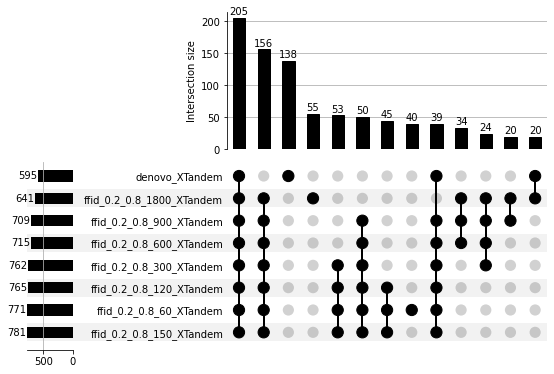

In [87]:
create_quantified_peptide_upsetplot(df=data2['XTandem'], q_cutoff=0, min_subset_size=20)

## Focus on `peak_width` = 60

Focusing on `peak_width` of 60, we see that 16% to 33% of the peptides are shared across all 3 search engines. When we remove features with quality score below 0 for FFId, the percentage of shared peptides are now 27% to 44%

In [57]:
data3 = {}
for se, df in data2.items():
    df = df[[f'denovo_{se}_intensity', f"denovo_{se}_quality", f"ffid_0.2_0.8_60_{se}_intensity", f"ffid_0.2_0.8_60_{se}_quality"]] \
        .dropna(how='all')
    key_mapper = {
        f'denovo_{se}_intensity': 'denovo',
        f'denovo_{se}_quality': 'denovo_quality',
        f'ffid_0.2_0.8_60_{se}_intensity': 'ffid',
        f'ffid_0.2_0.8_60_{se}_quality': 'ffid_quality'
    }
    df = df[list(key_mapper.keys())].rename(key_mapper, axis=1)
    df = df[df['denovo'].notnull() | df['ffid'].notnull()]
    df['shared'] = [(not np.isnan(row['denovo'])) and (not np.isnan(row['ffid'])) for _,row in df.iterrows()]
    data3[se] = df

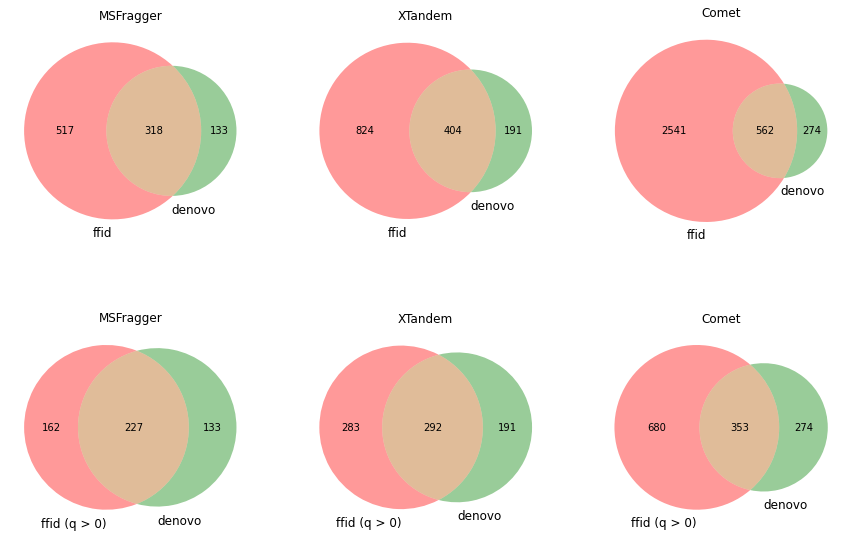

In [68]:
q_cutoff = 0
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15,10))
i = 0
for se, df in data3.items():
    venn_data_1 = [0,0,0]
    venn_data_2 = [0,0,0]
    for _,row in df.iterrows():
        if not np.isnan(row['denovo']) and not np.isnan(row['ffid']):
            venn_data_1[2] += 1
            if row['ffid_quality'] > q_cutoff:
                venn_data_2[2] += 1
        elif not np.isnan(row['denovo']):
            venn_data_1[1] += 1
            venn_data_2[1] += 1
        else:
            venn_data_1[0] += 1
            if row['ffid_quality'] > q_cutoff:
                venn_data_2[0] += 1
    venn2(subsets = venn_data_1, set_labels=['ffid', 'denovo'], ax=axes[0][i], )
    venn2(subsets = venn_data_2, set_labels=['ffid (q > 0)', 'denovo'], ax=axes[1][i])
    axes[0][i].set_title(se)
    axes[1][i].set_title(se)
    i += 1

## Are peptides unique to FFId having lower quality?

It seems like the case, but still a surprisingly larg number of PSMs unique to FFId 

Text(0.5, 1.0, 'Unique to FFId')

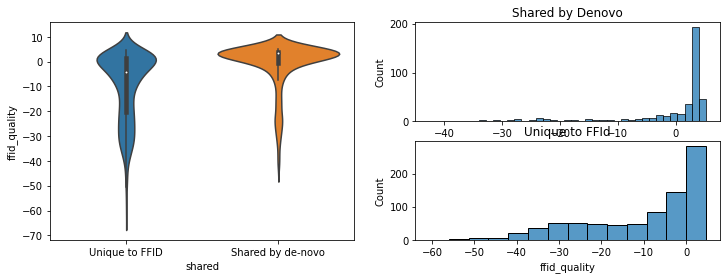

In [102]:
plt.figure(figsize=(12,4))
ax1 = plt.subplot(1,2,1)
ax2 = plt.subplot(2,2,2)
ax3 = plt.subplot(2,2,4)
df = data3['XTandem']
sns.violinplot(data=df, x = 'shared', y='ffid_quality', ax=ax1)
ax1.set_xticklabels(labels=['Unique to FFID', 'Shared by de-novo'])
sns.histplot(data=df[df['shared'] == True], x='ffid_quality', ax=ax2)
ax2.set_title('Shared by Denovo')
sns.histplot(data=df[df['shared'] == False], x='ffid_quality', ax=ax3)
ax3.set_title('Unique to FFId')

## Are peptides unique to FFId having lower intensity?

Seems like there are peptides that are unique to FFId have pretty high intensity.

Text(0.5, 1.0, 'Unique to FFId (zoom in)')

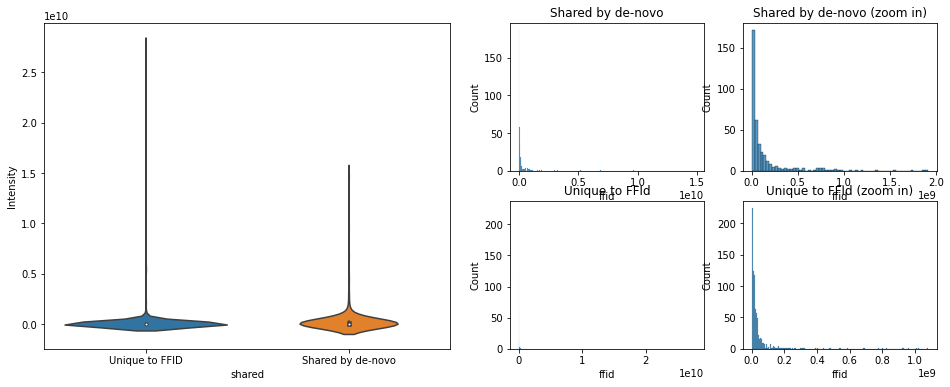

In [118]:
df = data3['XTandem']
plt.figure(figsize=(16,6))
ax1 = plt.subplot(1,2,1)
ax2 = plt.subplot(2,4,3)
ax3 = plt.subplot(2,4,7)
ax4 = plt.subplot(2,4,4)
ax5 = plt.subplot(2,4,8)
sns.violinplot(data=df, x = 'shared', y='ffid', ax=ax1)
ax1.set_xticklabels(labels=['Unique to FFID', 'Shared by de-novo'])
ax1.set_ylabel('Intensity')
sns.histplot(data=df[df['shared'] == True], x='ffid', ax=ax2)
ax2.set_title('Shared by de-novo')
sns.histplot(data=df[df['shared'] == False], x='ffid', ax=ax3)
ax3.set_title('Unique to FFId')
sns.histplot(data=df[(df['shared'] == True) & (df['ffid'] < 0.2e10)], x='ffid', ax=ax4)
ax4.set_title('Shared by de-novo (zoom in)')
sns.histplot(data=df[(df['shared'] == False) & (df['ffid'] < 0.2e10)], x='ffid', ax=ax5)
ax5.set_title('Unique to FFId (zoom in)')

## Are peptides with lower intensity having lower quality?

The figures below are the intensities called by two workflow. They correlate with each other pretty well, but seems like the ones that FFId have very low intesntiy tend to have lower quality

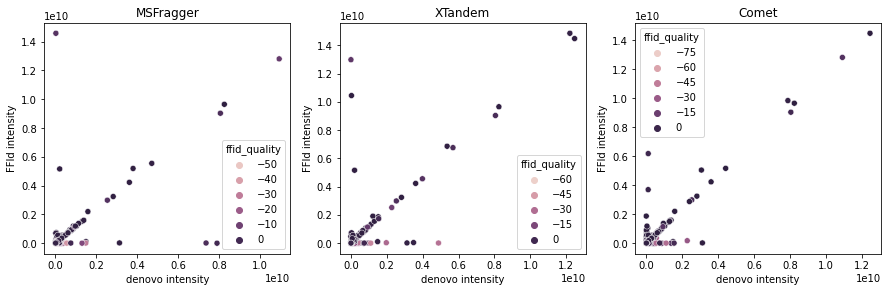

In [117]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15,4.25))
i = 0
for se, df in data3.items():
    ax = axes[i]
    sns.scatterplot(data=df, x='denovo', y='ffid', hue='ffid_quality', ax=ax)
    ax.set_title(se)
    ax.set_xlabel('denovo intensity')
    ax.set_ylabel('FFId intensity')
    i += 1

Only a few peptides with low quality have high intensity.

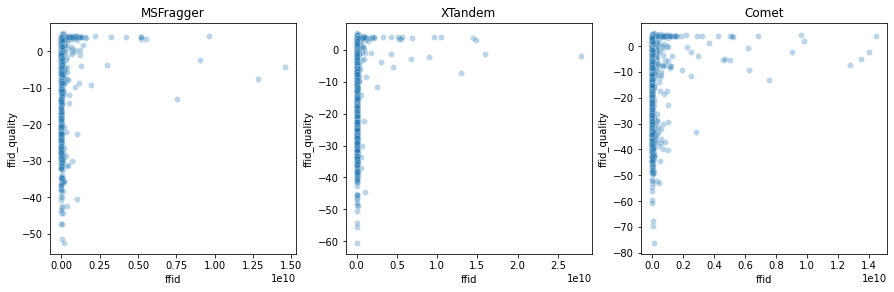

In [111]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15,4.25))
i = 0
for se, df in data3.items():
    ax = axes[i]
    sns.scatterplot(data=df, x='ffid', y='ffid_quality', ax=ax, alpha = 0.3)
    ax.set_title(se)
    i += 1

## Are peptides not shared having lower intensity?

The pattern isn't clear.

[Text(0, 0, 'Unique to FFId'), Text(1, 0, 'Shared by de-novo')]

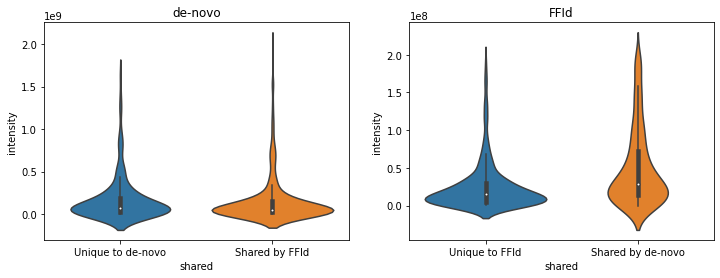

In [116]:
df = data3['XTandem']
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,4))
sns.violinplot(data=df[df['denovo'].notnull() & (df['denovo'] < 0.2e10)], x='shared', y = 'denovo', ax=axes[0])
axes[0].set_title('de-novo')
axes[0].set_ylabel('intensity')
axes[0].set_xticklabels(labels=['Unique to de-novo', 'Shared by FFId'])
sns.violinplot(data=df[df['ffid'].notnull() & (df['ffid'] < 2e8)], x='shared', y = 'ffid', ax=axes[1])
axes[1].set_title('FFId')
axes[1].set_ylabel('intensity')
axes[1].set_xticklabels(labels=['Unique to FFId', 'Shared by de-novo'])